In [13]:
import pandas as pd
import numpy as np
import seaborn as sns

In [14]:
df=pd.read_csv("C:/Users/ELCOT/Desktop/weather_classification_data.csv")
df

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy
...,...,...,...,...,...,...,...,...,...,...,...
13195,10.0,74,14.5,71.0,overcast,1003.15,1,Summer,1.0,mountain,Rainy
13196,-1.0,76,3.5,23.0,cloudy,1067.23,1,Winter,6.0,coastal,Snowy
13197,30.0,77,5.5,28.0,overcast,1012.69,3,Autumn,9.0,coastal,Cloudy
13198,3.0,76,10.0,94.0,overcast,984.27,0,Winter,2.0,inland,Snowy


### BASIC UNDERSTANDING

In [15]:
df.columns

Index(['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)',
       'Cloud Cover', 'Atmospheric Pressure', 'UV Index', 'Season',
       'Visibility (km)', 'Location', 'Weather Type'],
      dtype='str')

In [16]:
df.shape

(13200, 11)

In [17]:
df.index

RangeIndex(start=0, stop=13200, step=1)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  float64
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  float64
 4   Cloud Cover           13200 non-null  str    
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  str    
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  str    
 10  Weather Type          13200 non-null  str    
dtypes: float64(5), int64(2), str(4)
memory usage: 1.5 MB


In [19]:
df.dtypes

Temperature             float64
Humidity                  int64
Wind Speed              float64
Precipitation (%)       float64
Cloud Cover                 str
Atmospheric Pressure    float64
UV Index                  int64
Season                      str
Visibility (km)         float64
Location                    str
Weather Type                str
dtype: object

In [20]:
df.describe()

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
count,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000
mean,19.127576,68.710833,9.832197,53.644394,1005.827896,4.005758,5.462917
std,17.386327,20.194248,6.908704,31.946541,37.199589,3.856600,3.371499
min,-25.000000,20.000000,0.000000,0.000000,800.120000,0.000000,0.000000
25%,4.000000,57.000000,5.000000,19.000000,994.800000,1.000000,3.000000
50%,21.000000,70.000000,9.000000,58.000000,1007.650000,3.000000,5.000000
75%,31.000000,84.000000,13.500000,82.000000,1016.772500,7.000000,7.500000
max,109.000000,109.000000,48.500000,109.000000,1199.210000,14.000000,20.000000


In [21]:
df.rename(columns={"Precipitation (%)":"Precipitation","Visibility (km)":"Visibility"},inplace=True)

### HANDLING NULL

In [22]:
df.isnull().sum()

Temperature             0
Humidity                0
Wind Speed              0
Precipitation           0
Cloud Cover             0
Atmospheric Pressure    0
UV Index                0
Season                  0
Visibility              0
Location                0
Weather Type            0
dtype: int64

### HANDLING OUTLIERS

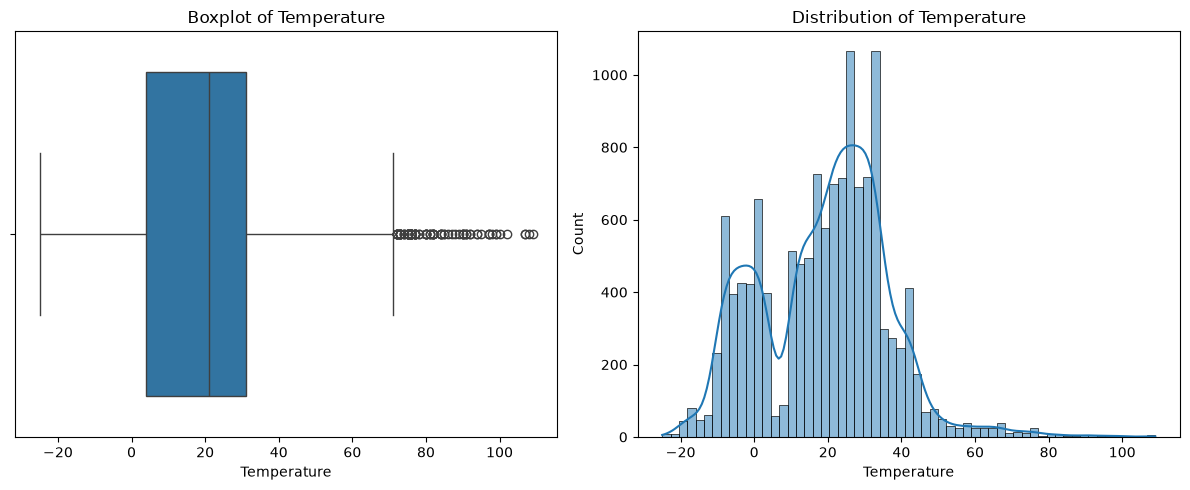

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Subplot 1: Boxplot
plt.subplot(1, 2, 1)
sns.boxplot(x="Temperature", data=df)
plt.title("Boxplot of Temperature")

# Subplot 2: Histogram with KDE
plt.subplot(1, 2, 2)
sns.histplot(x="Temperature", data=df, kde=True)
plt.title("Distribution of Temperature")

plt.tight_layout()
plt.show()

In [24]:
df['Temperature']=df['Temperature'].clip(upper=50)

<Axes: xlabel='Temperature'>

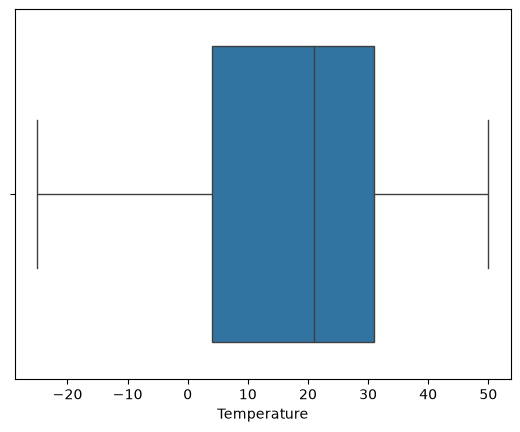

In [25]:
sns.boxplot(x='Temperature',data=df)

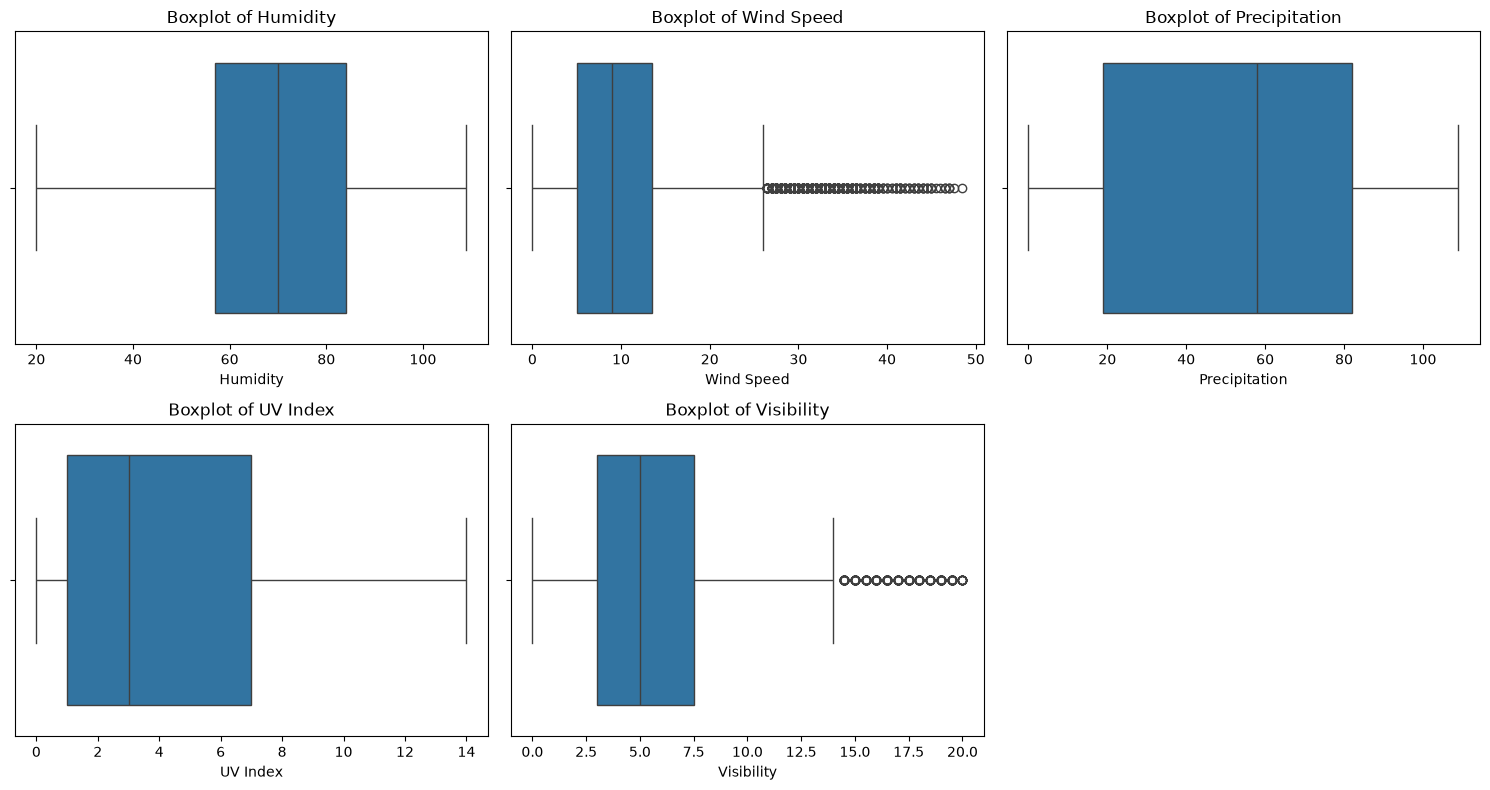

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 8))

# Subplot 1: Humidity
plt.subplot(2, 3, 1)
sns.boxplot(x="Humidity", data=df)
plt.title("Boxplot of Humidity")

# Subplot 2: Wind Speed
plt.subplot(2, 3, 2)
sns.boxplot(x="Wind Speed", data=df)
plt.title("Boxplot of Wind Speed")

# Subplot 3: Precipitation
plt.subplot(2, 3, 3)
sns.boxplot(x="Precipitation", data=df)
plt.title("Boxplot of Precipitation")

# Subplot 4: UV Index
plt.subplot(2, 3, 4)
sns.boxplot(x="UV Index", data=df)
plt.title("Boxplot of UV Index")

# Subplot 5: Visibility
plt.subplot(2, 3, 5)
sns.boxplot(x="Visibility", data=df)
plt.title("Boxplot of Visibility")

plt.tight_layout()
plt.show()

In [27]:
df["Cloud Cover"].value_counts()

Cloud Cover
overcast         6090
partly cloudy    4560
clear            2139
cloudy            411
Name: count, dtype: int64

In [28]:
df["Season"].value_counts()

Season
Winter    5610
Spring    2598
Autumn    2500
Summer    2492
Name: count, dtype: int64

In [29]:
df["Location"].value_counts()

Location
inland      4816
mountain    4813
coastal     3571
Name: count, dtype: int64

### FEATURE SELECTION(Hypthesis Testing)

In [30]:
#Annova
from sklearn.feature_selection import f_classif
import pandas as pd

# Assume X contains only your numerical features
# and y is your 'Weather Type' target column
X = df[
    [
        "Temperature",
        "Humidity",
        "Wind Speed",
        "Precipitation",
        "Atmospheric Pressure",
        "Visibility",
    ]
]
y = df["Weather Type"]

f_scores, p_values = f_classif(X, y)

# Create a DataFrame to view the results clearly
feature_scores = pd.DataFrame(
    {"Feature": X.columns, "F-Score": f_scores, "P-Value": p_values}
)
print(feature_scores.sort_values(by="F-Score", ascending=False))

                Feature      F-Score        P-Value
0           Temperature  5675.687440   0.000000e+00
3         Precipitation  3776.770221   0.000000e+00
5            Visibility  1927.720840   0.000000e+00
1              Humidity  1911.351373   0.000000e+00
2            Wind Speed   877.147222   0.000000e+00
4  Atmospheric Pressure   330.396542  7.092867e-207


In [31]:
df["Weather Type"].unique()

<ArrowStringArray>
['Rainy', 'Cloudy', 'Sunny', 'Snowy']
Length: 4, dtype: str

In [32]:
import pandas as pd
from scipy.stats import chi2_contingency

observed = pd.crosstab(df['Weather Type'], df['Cloud Cover'])

chi2_stat, p_val, dof, expected = chi2_contingency(observed)

if p_val < 0.05:
    print("There is relationship .")  # there is relationship
else:
    print("There is no difference between smoking status and day.") # there is no relationship

There is relationship .


In [33]:
import pandas as pd
from scipy.stats import chi2_contingency

observed = pd.crosstab(df['Weather Type'], df['UV Index'])

chi2_stat, p_val, dof, expected = chi2_contingency(observed)

if p_val < 0.05:
    print("There is relationship .")  # there is relationship
else:
    print("There is no difference between smoking status and day.") # there is no relationship

There is relationship .


In [35]:
import pandas as pd
from scipy.stats import chi2_contingency

observed = pd.crosstab(df['Weather Type'], df['Season'])

chi2_stat, p_val, dof, expected = chi2_contingency(observed)

if p_val < 0.05:
    print("There is relationship .")  # there is relationship
else:
    print("There is no difference between smoking status and day.") # there is no relationship

There is relationship .


In [36]:
import pandas as pd
from scipy.stats import chi2_contingency

observed = pd.crosstab(df['Weather Type'], df['Location'])

chi2_stat, p_val, dof, expected = chi2_contingency(observed)

if p_val < 0.05:
    print("There is relationship .")  # there is relationship
else:
    print("There is no difference between smoking status and day.") # there is no relationship

There is relationship .


### ENCODING

In [38]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
df["Cloud Cover"]=label.fit_transform(df["Cloud Cover"])

In [39]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
df["Season"]=label.fit_transform(df["Season"])

In [40]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
df["Location"]=label.fit_transform(df["Location"])

In [41]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
df["Weather Type"]=label.fit_transform(df["Weather Type"])

In [42]:
df.head()

,Temperature,Humidity,Wind Speed,Precipitation,Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility,Location,Weather Type
0,14.0,73,9.5,82.0,3,1010.82,2,3,3.5,1,1
1,39.0,96,8.5,71.0,3,1011.43,7,1,10.0,1,0
2,30.0,64,7.0,16.0,0,1018.72,5,1,5.5,2,3
3,38.0,83,1.5,82.0,0,1026.25,7,1,1.0,0,3
4,27.0,74,17.0,66.0,2,990.67,1,3,2.5,2,1


### Splitting x and y

In [43]:
x=df.iloc[:,0:10]
y=df.iloc[:,10]

### TRAIN and TEST

In [44]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [51]:
df["Weather Type"].value_counts()

Weather Type
1    3300
0    3300
3    3300
2    3300
Name: count, dtype: int64

### SCALING

In [52]:
from sklearn.preprocessing import StandardScaler
scale=StandardScaler()
x_train_scaled=scale.fit_transform(x_train)
x_test_scaled=scale.transform(x_test)

### Model Building, Training Testing Accuracy, MAE, MSE, RMSE, Hyperparameter Tuning

In [53]:
from sklearn.linear_model import LogisticRegression
model1=LogisticRegression()
model1.fit(x_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [54]:
#For Training
y_tr1=model1.predict(x_train_scaled)
from sklearn.metrics import accuracy_score
train_accuracy1=accuracy_score(y_train,y_tr1)
train_accuracy1

0.8579545454545454

In [55]:
# FOR TESTING
y_pred1=model1.predict(x_test_scaled)
from sklearn.metrics import accuracy_score
test_accuracy1=accuracy_score(y_test,y_pred1)
test_accuracy1

0.8477272727272728

In [56]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred1))

              precision    recall  f1-score   support

           0       0.81      0.81      0.81       651
           1       0.84      0.83      0.83       647
           2       0.89      0.94      0.92       701
           3       0.85      0.80      0.82       641

    accuracy                           0.85      2640
   macro avg       0.85      0.85      0.85      2640
weighted avg       0.85      0.85      0.85      2640



In [65]:
from sklearn.neighbors import KNeighborsClassifier
model2=KNeighborsClassifier( metric= 'manhattan', n_neighbors = 5 )
model2.fit(x_train_scaled,y_train)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'manhattan'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[0,1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'ma...an'


In [66]:
#For Training
y_tr2=model2.predict(x_train_scaled)
from sklearn.metrics import accuracy_score
train_accuracy2=accuracy_score(y_train,y_tr2)
train_accuracy2

0.9289772727272727

In [67]:
#Testing Accuracy
y_pred2=model2.predict(x_test_scaled)
test_accuracy2=accuracy_score(y_test,y_pred2)
test_accuracy2

0.8946969696969697

In [68]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred2))

              precision    recall  f1-score   support

           0       0.86      0.87      0.86       651
           1       0.86      0.88      0.87       647
           2       0.93      0.95      0.94       701
           3       0.93      0.88      0.91       641

    accuracy                           0.89      2640
   macro avg       0.89      0.89      0.89      2640
weighted avg       0.90      0.89      0.89      2640



In [49]:
from sklearn.model_selection import GridSearchCV

KNN_PARAMETER = {'n_neighbors': [3, 5, 7, 11],'metric': ['euclidean', 'manhattan'],}


grid_search = GridSearchCV(KNeighborsClassifier(), KNN_PARAMETER, cv=5)


grid_search.fit(x_train, y_train)


print(grid_search.best_params_)

{'metric': 'manhattan', 'n_neighbors': 5}


In [ ]:
#Without Hyperparameter Tuning
#Training - 0.9273674242424242
#Testing - 0.8931818181818182

In [102]:
from sklearn.svm import SVC
model3=SVC()
model3.fit(x_train_scaled,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [104]:
#Training Accuracy
y_tr3=model3.predict(x_train_scaled)
train_accuracy3=accuracy_score(y_tr3,y_train)
train_accuracy3

0.9420454545454545

In [106]:
#Testing Accuracy
y_pred3=model3.predict(x_test_scaled)
test_accuracy3=accuracy_score(y_pred3,y_test)
test_accuracy3

0.9056818181818181

In [107]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred3))

              precision    recall  f1-score   support

           0       0.87      0.89      0.88       651
           1       0.89      0.90      0.90       647
           2       0.94      0.94      0.94       701
           3       0.91      0.89      0.90       641

    accuracy                           0.91      2640
   macro avg       0.91      0.90      0.90      2640
weighted avg       0.91      0.91      0.91      2640



In [72]:
from sklearn.tree import DecisionTreeClassifier
model4=DecisionTreeClassifier(criterion = 'gini', max_depth =10, min_samples_leaf= 2, min_samples_split= 10)
model4.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

In [73]:
#Training Accuracy
y_tr4=model4.predict(x_train)
from sklearn.metrics import accuracy_score
tr_accuracy4=accuracy_score(y_tr4,y_train)
tr_accuracy4

0.9481060606060606

In [74]:
#Testing Accuracy
y_te4=model4.predict(x_test)
from sklearn.metrics import accuracy_score
tr_test4=accuracy_score(y_test,y_te4)
tr_test4

0.9128787878787878

In [75]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_te4))

              precision    recall  f1-score   support

           0       0.88      0.90      0.89       651
           1       0.87      0.92      0.89       647
           2       0.95      0.94      0.94       701
           3       0.96      0.89      0.93       641

    accuracy                           0.91      2640
   macro avg       0.91      0.91      0.91      2640
weighted avg       0.91      0.91      0.91      2640



In [ ]:
#Without Hyperparameter Tuning
#Training - 1.0
#Testing - 0.9045454545454545

In [65]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

param_grid = {'criterion': ['gini', 'entropy'],'max_depth': [None, 3, 5, 10],'min_samples_split': [2, 5, 10],'min_samples_leaf': [1, 2, 4]
}

dt=DecisionTreeClassifier()
# GridSearchCV
grid_search = GridSearchCV(estimator=dt,param_grid=param_grid,cv=5,scoring='accuracy',)

# Train
grid_search.fit(x_train, y_train)

# Best parameters
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best CV Accuracy: 0.9119318181818181


In [79]:
from sklearn.ensemble import RandomForestClassifier
model5=RandomForestClassifier(max_depth= 14, min_samples_leaf=1, min_samples_split= 5, n_estimators= 99)
model5.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",99
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",14
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [80]:
#Training Accuracy
y_tr5=model5.predict(x_train)
from sklearn.metrics import accuracy_score
tr_accuracy5=accuracy_score(y_tr5,y_train)
tr_accuracy5

0.9980113636363637

In [81]:
#Testing Accuracy
y_te5=model5.predict(x_test)
from sklearn.metrics import accuracy_score
tr_test5=accuracy_score(y_test,y_te5)
tr_test5

0.915530303030303

In [121]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# MODEL
model = RandomForestClassifier()

# PARAMETERS
param_dist = {
    'n_estimators': randint(50, 300),
    'max_depth': randint(1, 20),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10)
}

# RANDOM SEARCH
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

# FIT
random_search.fit(x_train, y_train)

# OUTPUT
print("Best Parameters:", random_search.best_params_)
print("Best Score:", random_search.best_score_)

Best Parameters: {'max_depth': 14, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 99}
Best Score: 0.915435606060606


In [132]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_te5))

              precision    recall  f1-score   support

           0       0.88      0.90      0.89       651
           1       0.91      0.92      0.91       647
           2       0.93      0.94      0.94       701
           3       0.95      0.91      0.93       641

    accuracy                           0.92      2640
   macro avg       0.92      0.92      0.92      2640
weighted avg       0.92      0.92      0.92      2640



In [ ]:
#Without Hyperparameter Tuning
#Training - 1.0
#Testing - 0.9140151515151516

In [6]:
import pandas as pd

comparison_data = {
    "Model": [
        "Logistic Regression",
        "SVC",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Train Score": [0.86, 0.94, 0.93, 0.95, 0.99],
    "Test Score": [0.85, 0.91, 0.89, 0.91, 0.92],
    "Accuracy": [0.85, 0.91, 0.89, 0.91, 0.92],
    "Recall": [0.85, 0.91, 0.89, 0.91, 0.92],
    "F1-Score": [0.85, 0.91, 0.89, 0.91, 0.92],
    "Gap": [0.01, 0.03, 0.04, 0.04, 0.07],
    "Generalization": [
        "Well Generalized",
        "Best Generalized",
        "Slight Overfit",
        "Slight Overfit",
        "Well Generalized "
    ],
    "Bias-Variance": [
        "Balanced",
        "Balanced",
        "Moderate Variance",
        "Moderate Variance",
        "Balanced"
    ],
    "Best Generalized Model": [
        "No",
        "YES",
        "No",
        "No",
        "No "
    ]
}

comparison = pd.DataFrame(comparison_data)
comparison

,Model,Train Score,Test Score,Accuracy,Recall,F1-Score,Gap,Generalization,Bias-Variance,Best Generalized Model
0,Logistic Regression,0.86,0.85,0.85,0.85,0.85,0.01,Well Generalized,Balanced,No
1,SVC,0.94,0.91,0.91,0.91,0.91,0.03,Best Generalized,Balanced,YES
2,KNN,0.93,0.89,0.89,0.89,0.89,0.04,Slight Overfit,Moderate Variance,No
3,Decision Tree,0.95,0.91,0.91,0.91,0.91,0.04,Slight Overfit,Moderate Variance,No
4,Random Forest,0.99,0.92,0.92,0.92,0.92,0.07,Well Generalized,Balanced,No
